In [1]:
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/autos/imports-85.data"
DATA = Path("data")
FIGS = Path("figures")
DATA.mkdir(exist_ok=True)
FIGS.mkdir(exist_ok=True)
RAW = DATA / "imports-85.data"
if not RAW.exists():
    urlretrieve(URL, RAW)

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
plt.rcParams.update({
    "axes.edgecolor": "#52514e",
    "axes.labelcolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "axes.axisbelow": True,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
})

print("pandas", pd.__version__, "numpy", np.__version__)

pandas 3.0.2 numpy 2.4.4


In [2]:
headers = ["symboling", "normalized-losses", "make", "fuel-type", "aspiration",
           "num-of-doors", "body-style", "drive-wheels", "engine-location",
           "wheel-base", "length", "width", "height", "curb-weight", "engine-type",
           "num-of-cylinders", "engine-size", "fuel-system", "bore", "stroke",
           "compression-ratio", "horsepower", "peak-rpm", "city-mpg",
           "highway-mpg", "price"]
df = pd.read_csv(RAW, names=headers)
print(df.shape)
df.head()

(205, 26)


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,length,width,height,curb-weight,engine-type,num-of-cylinders,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495
1,3,?,alfa-romero,gas,std,two,convertible,rwd,front,88.6,168.8,64.1,48.8,2548,dohc,four,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500
2,1,?,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,171.2,65.5,52.4,2823,ohcv,six,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500
3,2,164,audi,gas,std,four,sedan,fwd,front,99.8,176.6,66.2,54.3,2337,ohc,four,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950
4,2,164,audi,gas,std,four,sedan,4wd,front,99.4,176.6,66.4,54.3,2824,ohc,five,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450


In [3]:
df = df.replace("?", np.nan)
missing_data = df.isnull()
missing_before = missing_data.sum()
missing_before = missing_before[missing_before > 0]
print("missing cells:", int(missing_data.values.sum()))
missing_before.to_frame("NaN")

missing cells: 59


,NaN
normalized-losses,41
num-of-doors,2
bore,4
stroke,4
horsepower,2
peak-rpm,2
price,4


In [4]:
for column in missing_before.index:
    print(column, missing_data[column].value_counts().to_dict())

normalized-losses {False: 164, True: 41}
num-of-doors {False: 203, True: 2}
bore {False: 201, True: 4}
stroke {False: 201, True: 4}
horsepower {False: 203, True: 2}
peak-rpm {False: 203, True: 2}
price {False: 201, True: 4}


In [5]:
numeric_cols = ["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]
df[numeric_cols] = df[numeric_cols].astype("float")
df.dtypes.value_counts()

float64    11
str        10
int64       5
Name: count, dtype: int64

In [6]:
avg_norm_loss = df["normalized-losses"].mean(axis=0)
print("Average of normalized-losses:", avg_norm_loss)
df["normalized-losses"] = df["normalized-losses"].fillna(avg_norm_loss)

avg_bore = df["bore"].mean(axis=0)
print("Average of bore:", avg_bore)
df["bore"] = df["bore"].fillna(avg_bore)

Average of normalized-losses: 122.0
Average of bore: 3.3297512437810943


In [7]:
stroke_nan_rows = df.index[df["stroke"].isnull()].tolist()
avg_stroke = df["stroke"].mean(axis=0)
print("Average of stroke:", avg_stroke)
df["stroke"] = df["stroke"].fillna(avg_stroke)
print("NaN in stroke:", df["stroke"].isnull().sum())
df.loc[stroke_nan_rows, ["make", "engine-type", "bore", "stroke"]]

Average of stroke: 3.255422885572139
NaN in stroke: 0


,make,engine-type,bore,stroke
55,mazda,rotor,3.329751,3.255423
56,mazda,rotor,3.329751,3.255423
57,mazda,rotor,3.329751,3.255423
58,mazda,rotor,3.329751,3.255423


In [8]:
print("rows without price:", df["price"].isnull().sum(),
      "shape after dropna(price):", df.dropna(subset=["price"]).shape)
fill_report = {}
for column in df.columns[df.isnull().any()]:
    if pd.api.types.is_numeric_dtype(df[column]):
        value = df[column].mean()
        rule = "mean"
    else:
        value = df[column].mode()[0]
        rule = "mode"
    fill_report[column] = (int(df[column].isnull().sum()), rule, value)
    df[column] = df[column].fillna(value)
print("NaN left:", int(df.isnull().sum().sum()))
pd.DataFrame(fill_report, index=["NaN", "rule", "value"]).T

rows without price: 4 shape after dropna(price): (201, 26)
NaN left: 0


,NaN,rule,value
num-of-doors,2,mode,four
horsepower,2,mean,104.256158
peak-rpm,2,mean,5125.369458
price,4,mean,13207.129353


In [9]:
df[["normalized-losses"]] = df[["normalized-losses"]].astype("int")
df[["horsepower"]] = df[["horsepower"]].astype("int")
df[["price", "peak-rpm", "bore", "stroke"]] = df[["price", "peak-rpm", "bore", "stroke"]].astype("float")
df[["normalized-losses", "bore", "stroke", "horsepower", "peak-rpm", "price"]].dtypes

normalized-losses      int64
bore                 float64
stroke               float64
horsepower             int64
peak-rpm             float64
price                float64
dtype: object

In [10]:
df["city-L/100km"] = 235 / df["city-mpg"]
df["highway-L/100km"] = 235 / df["highway-mpg"]
df[["city-mpg", "city-L/100km", "highway-mpg", "highway-L/100km"]].head()

,city-mpg,city-L/100km,highway-mpg,highway-L/100km
0,21,11.190476,27,8.703704
1,21,11.190476,27,8.703704
2,19,12.368421,26,9.038462
3,24,9.791667,30,7.833333
4,18,13.055556,22,10.681818


In [11]:
height_raw = df["height"].copy()
h_min, h_max = height_raw.min(), height_raw.max()
h_mean, h_std = height_raw.mean(), height_raw.std()
h_range = np.ptp(height_raw)
print("min", h_min, "max", h_max, "range", round(h_range, 4), "mean", round(h_mean, 4), "std", round(h_std, 4))
df["height"] = height_raw.sub(h_min) / h_range
comparison = pd.DataFrame({
    "height_raw": height_raw,
    "min_max": df["height"],
    "simple_scaling": height_raw / h_max,
    "z_score": height_raw.sub(h_mean) / h_std,
})
comparison.describe().loc[["count", "mean", "std", "min", "max"]].round(4)

min 47.8 max 59.8 range 12.0 mean 53.7249 std 2.4435


,height_raw,min_max,simple_scaling,z_score
count,205.0000,205.0000,205.0000,205.0000
mean,53.7249,0.4937,0.8984,-0.0000
std,2.4435,0.2036,0.0409,1.0000
min,47.8000,0.0000,0.7993,-2.4247
max,59.8000,1.0000,1.0000,2.4862


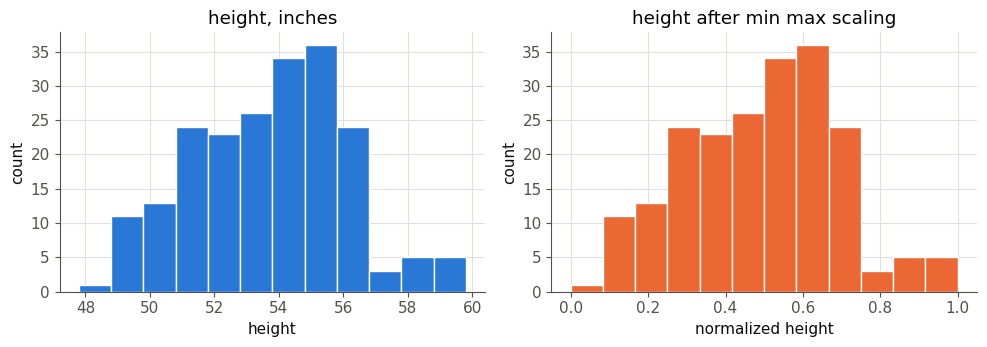

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(height_raw, bins=12, color=PALETTE[0], edgecolor="white")
axes[0].set_title("height, inches")
axes[0].set_xlabel("height")
axes[0].set_ylabel("count")
axes[1].hist(df["height"], bins=12, color=PALETTE[1], edgecolor="white")
axes[1].set_title("height after min max scaling")
axes[1].set_xlabel("normalized height")
axes[1].set_ylabel("count")
fig.tight_layout()
fig.savefig(FIGS / "height_normalization.png", dpi=200)

In [13]:
bins = np.linspace(df["horsepower"].min(), df["horsepower"].max(), 4)
group_names = ["Low", "Medium", "High"]
df["horsepower-binned"] = pd.cut(df["horsepower"], bins, labels=group_names, include_lowest=True)
print("bins:", bins.round(2).tolist())
df["horsepower-binned"].value_counts().reindex(group_names)

bins: [48.0, 128.0, 208.0, 288.0]


horsepower-binned
Low       163
Medium     40
High        2
Name: count, dtype: int64

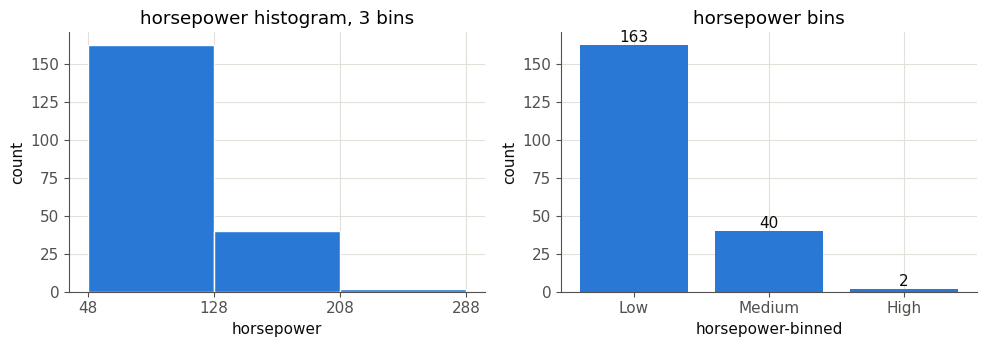

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(df["horsepower"], bins=bins, color=PALETTE[0], edgecolor="white")
axes[0].set_xticks(bins)
axes[0].set_title("horsepower histogram, 3 bins")
axes[0].set_xlabel("horsepower")
axes[0].set_ylabel("count")
counts = df["horsepower-binned"].value_counts().reindex(group_names)
axes[1].bar(group_names, counts.values, color=PALETTE[0])
for x, y in zip(group_names, counts.values):
    axes[1].text(x, y + 2, str(y), ha="center", color="#0b0b0b")
axes[1].set_title("horsepower bins")
axes[1].set_xlabel("horsepower-binned")
axes[1].set_ylabel("count")
fig.tight_layout()
fig.savefig(FIGS / "horsepower_binning.png", dpi=200)

In [15]:
dummy_variable_2 = pd.get_dummies(df["aspiration"], dtype=int)
dummy_variable_2 = dummy_variable_2.rename(columns={"std": "aspiration-std", "turbo": "aspiration-turbo"})
print(dummy_variable_2.sum().to_dict())
dummy_variable_2.head()

{'aspiration-std': 168, 'aspiration-turbo': 37}


,aspiration-std,aspiration-turbo
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


In [16]:
df = pd.concat([df, dummy_variable_2], axis=1)
df = df.drop("aspiration", axis=1)
print("aspiration" in df.columns, df.shape)
df[["make", "fuel-type", "aspiration-std", "aspiration-turbo", "height", "horsepower-binned"]].head()

False (205, 30)


,make,fuel-type,aspiration-std,aspiration-turbo,height,horsepower-binned
0,alfa-romero,gas,1,0,0.083333,Low
1,alfa-romero,gas,1,0,0.083333,Low
2,alfa-romero,gas,1,0,0.383333,Medium
3,audi,gas,1,0,0.541667,Low
4,audi,gas,1,0,0.541667,Low


NaN after cleaning: 0 shape: (205, 30)


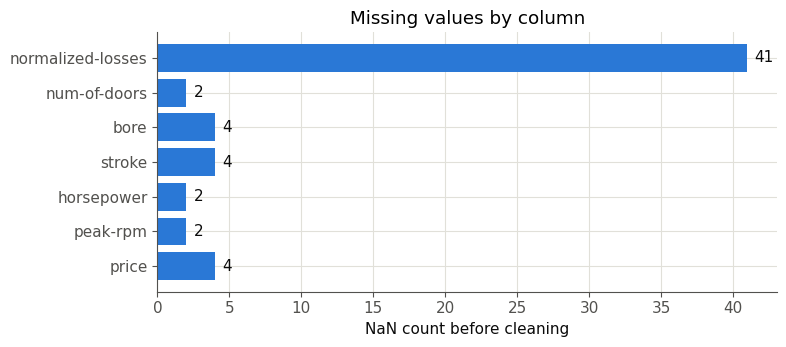

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(missing_before.index[::-1], missing_before.values[::-1], color=PALETTE[0])
for y, v in enumerate(missing_before.values[::-1]):
    ax.text(v + 0.5, y, str(v), va="center", color="#0b0b0b")
ax.set_xlabel("NaN count before cleaning")
ax.set_title("Missing values by column")
fig.tight_layout()
fig.savefig(FIGS / "missing_values.png", dpi=200)
print("NaN after cleaning:", int(df.isnull().sum().sum()), "shape:", df.shape)

In [18]:
df.to_csv(DATA / "auto_clean.csv", index=False)
df.dtypes.astype(str).value_counts()

float64     11
int64        9
str          9
category     1
Name: count, dtype: int64